# 02 · Value Iteration (planning)

**In this notebook**
- How Value Iteration works. It is a **planning** method: it knows the whole map and the rules, so the agent never has to move.
- **Convergence:** how quickly the values stop changing, one sweep at a time.
- The final **value** of every square (a colour map) and the resulting **policy** (arrows).
- How much work planning took: sweeps, updates and time.

Value Iteration finds the shortest route. Later notebooks use this route as the "best possible" answer to compare against.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from frozenlake_rl.config import CONFIG
from frozenlake_rl import env as fl, plotting as plot
from frozenlake_rl.experiments import load_vi, load_td, q_table
from frozenlake_rl.evaluate import greedy_policy, mean_and_ci, seeds_on_time_grid

plot.apply_style()
pd.set_option("display.precision", 3)
MAPS = list(CONFIG["maps"])          # ["4x4", "8x8"]
RERUN = False                        # True = ignore cached CSVs in results/ and recompute

## The idea

The **value** of a square, V(s), is the total reward the agent can expect from that square if it plays as well as
possible from then on. Squares close to the goal have high values. Squares far from the goal have lower values.

Value Iteration starts with every value at 0. It then keeps improving the values with this rule:

```
V(s)  =  best over all actions a  of  [ r  +  gamma × V(s') ]
```

In words: *the value of a square = the best you can get by taking one step and then carrying on from where you land.*

- **s**: the square the agent is on (the state).
- **a**: an action (left, down, right or up). "Best over all actions" means we try all four and keep the best.
- **r**: the reward for that step (+1 goal, −1 hole, −0.01 otherwise).
- **s'** ("s-prime"): the square the action leads to.
- **V(s')**: our current guess of the value of that next square.
- **gamma** (0.99): how much future reward is worth compared with reward now.

Holes and the goal end the episode, so their value is always 0 (there is nothing more to collect).

One **sweep** means using this rule once on every square that isn't a hole or the goal. We keep doing sweeps until the
**biggest change** in a sweep is smaller than **theta = 1e-8** (0.00000001). At that point the values have stopped changing.

Finally, the **policy** (what to do in each square) is: pick the action with the best `r + gamma × V(s')`.
This is called acting **greedily**.

In [2]:
vi = {m: load_vi(m, rerun=RERUN) for m in MAPS}
envs = {m: fl.make_env(m) for m in MAPS}
for m in MAPS:
    s = vi[m]["summary"].iloc[0]
    print(f"{m}: converged after {int(s['sweeps'])} sweeps; shortest route found = {int(s['optimal_steps'])} steps")

4x4: converged after 7 sweeps; shortest route found = 6 steps
8x8: converged after 15 sweeps; shortest route found = 14 steps


## Convergence

The plot shows the biggest value change in each sweep. The y-axis uses a **log scale**: each grid line is 10 times
smaller than the one above it. The dotted line is the stopping point, theta.

On non-slippery ice the values settle quickly. The goal's value spreads back one square per sweep.
While it is spreading, each sweep gives some square its first real value (going from 0 to about 0.8–0.9),
so the biggest change stays close to 1. Once the news has reached the start square, the next sweep changes nothing
at all (a change of exactly 0), and the method stops. So the number of sweeps is roughly the length of the shortest route:
**7 sweeps on 4x4 and 15 on 8x8**.

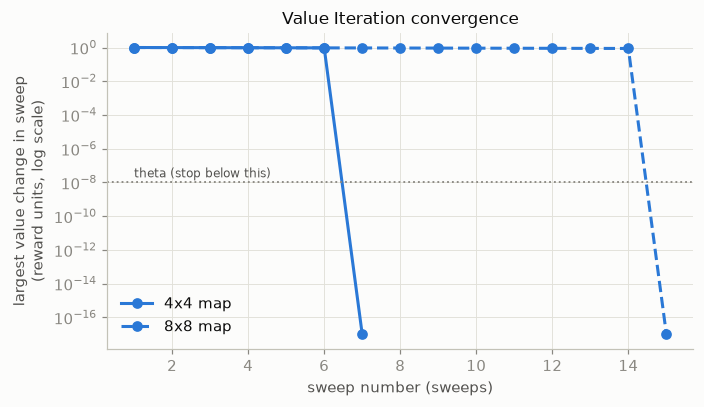

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for m, ls in zip(MAPS, ["-", "--"]):
    sw = vi[m]["sweeps"]
    # a change of exactly 0 can't be drawn on a log scale; show it at the bottom of the axis instead
    y = sw["max_delta"].clip(lower=1e-17)
    ax.plot(sw["sweep"], y, ls, marker="o", color=plot.COLORS["Value Iteration"], label=f"{m} map")
ax.axhline(CONFIG["value_iteration"]["theta"], color=plot.INK_MUTED, ls=":", lw=1.2)
ax.text(1, CONFIG["value_iteration"]["theta"] * 2, "theta (stop below this)", color=plot.INK_SECONDARY, fontsize=8)
ax.set_yscale("log")
ax.set_xlabel("sweep number (sweeps)")
ax.set_ylabel("largest value change in sweep\n(reward units, log scale)")
ax.set_title("Value Iteration convergence")
ax.legend()
plt.tight_layout(); plot.save_fig(fig, "02_vi_convergence"); plt.show()

A change of exactly 0 can't be drawn on a log scale, so the last sweep (where nothing changed) is drawn at the bottom of the plot.

## Values and policy

**Left:** the value of every square. Darker means a higher value, which means fewer steps to the goal.
**Right:** the action chosen in each square. The shaded line is the route the policy takes from S.

Often two actions are equally good (for example "down then right" and "right then down" take the same number of steps).
When there is a tie, we always pick the action with the lowest number (left < down < right < up), so the result is the same every time.

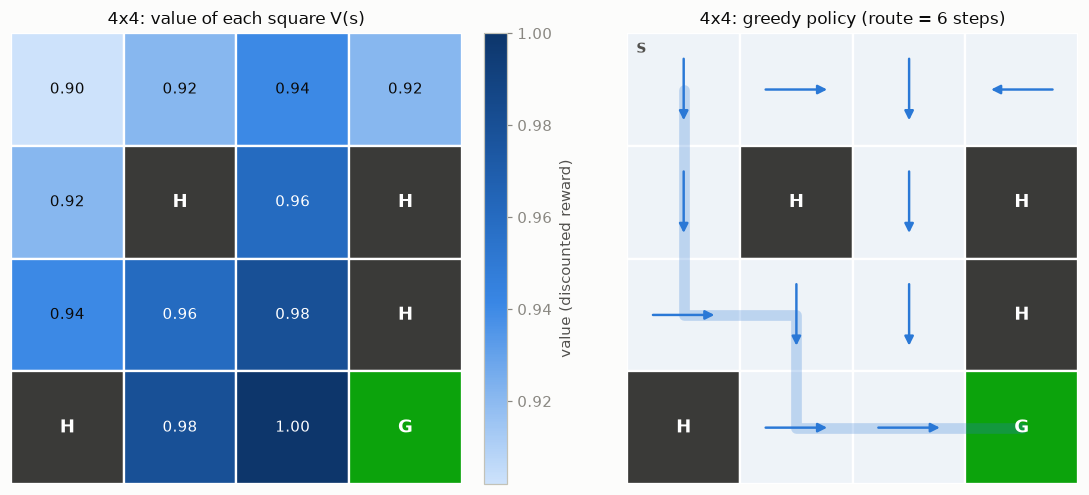

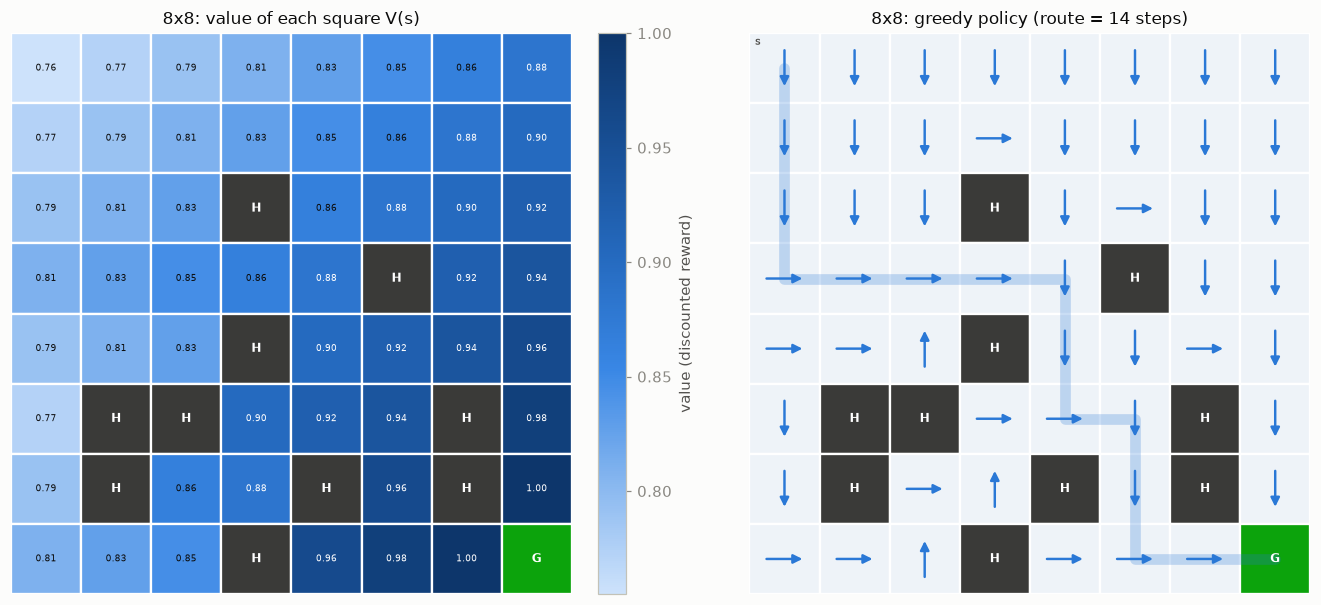

In [4]:
for m in MAPS:
    env, st = envs[m], vi[m]["states"]
    t, shape = fl.tiles(env), fl.grid_shape(env)
    path = fl.follow_policy(env, st["policy"].to_numpy())
    size = (11, 4.6) if m == "4x4" else (13, 5.6)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=size)
    plot.draw_values(a1, t, shape, st["value"], title=f"{m}: value of each square V(s)")
    plot.draw_policy(a2, t, shape, st["policy"], path=path, color=plot.COLORS["Value Iteration"],
                     title=f"{m}: greedy policy (route = {len(path) - 1} steps)")
    plt.tight_layout(); plot.save_fig(fig, f"02_vi_values_policy_{m}"); plt.show()

## How good is the policy after each sweep?

We can stop Value Iteration early and test the policy we'd get after each sweep. This testing happens after the timing,
so it isn't counted as planning time.
Early sweeps only "know" about squares near the goal. So the policy can't reach the goal from S until the goal's value
has spread all the way back to the start. Then the success rate jumps straight from 0% to 100%.

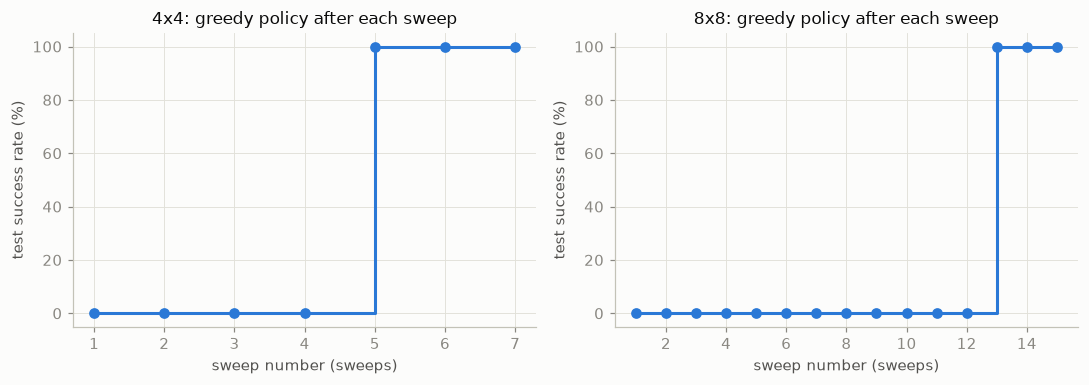

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=False)
for ax, m in zip(axes, MAPS):
    sw = vi[m]["sweeps"]
    ax.step(sw["sweep"], sw["success_rate"], where="post", color=plot.COLORS["Value Iteration"], marker="o")
    ax.set_xlabel("sweep number (sweeps)")
    ax.set_ylabel("test success rate (%)")
    ax.set_ylim(-5, 105)
    ax.set_title(f"{m}: greedy policy after each sweep")
plt.tight_layout(); plt.show()

## Planning cost

We count Value Iteration's work in **its own units**:
- **sweeps**: passes over the whole map;
- **state updates**: single uses of the update rule (sweeps × number of squares that aren't holes or the goal);
- **planning time**: measured on this computer. We ran planning 7 times and report the **median** (the middle value),
  because timings change a little from run to run.

These units are **not** the same as the training episodes used by Q-learning and SARSA (see notebook 05).

In [6]:
cost = pd.DataFrame({m: {
    "sweeps": int(vi[m]["summary"]["sweeps"].iloc[0]),
    "state updates": int(vi[m]["summary"]["state_updates"].iloc[0]),
    "planning time, median (ms)": 1000 * vi[m]["summary"]["planning_time_s_median"].iloc[0],
    "planning time, min–max (ms)": "{:.3f}–{:.3f}".format(1000 * vi[m]["summary"]["planning_time_s_min"].iloc[0],
                                                          1000 * vi[m]["summary"]["planning_time_s_max"].iloc[0]),
    "timing repeats": int(vi[m]["summary"]["timing_repeats"].iloc[0]),
    "test success rate (%)": 100 * vi[m]["test"]["success"].mean(),
    "path length (steps)": vi[m]["summary"]["optimal_steps"].iloc[0],
} for m in MAPS})
cost

,4x4,8x8
sweeps,7,15
state updates,77,795
"planning time, median (ms)",0.105,1.081
"planning time, min–max (ms)",0.096–0.118,1.059–1.086
timing repeats,7,7
test success rate (%),100.0,100.0
path length (steps),6.0,14.0


## Key points

- Value Iteration finds the **shortest route** on both maps (6 steps on 4x4, 14 on 8x8) without the agent ever moving.
  Both routes reach the goal 100% of the time.
- It needs only 7 sweeps (4x4) and 15 sweeps (8x8), and takes about 0.1 ms and 1 ms. But this only works because
  it is given the **full rules of the game**. In most real problems we don't have those rules, which is why we also look at learning methods.
- The number of sweeps grows with the distance from start to goal, and each sweep visits every square.
  So the cost grows quickly on bigger maps.